In [43]:
import sys
from pathlib import Path
import numpy as np

RAIZ_PROJETO = Path("..").resolve()
if str(RAIZ_PROJETO / "src") not in sys.path:
    sys.path.append(str(RAIZ_PROJETO / "src"))

from perceptron_pp import Perceptron, visualizacao

In [44]:
caminho_dados = RAIZ_PROJETO / "data" / "dataAll20262.txt"

if not caminho_dados.exists():
    raise FileNotFoundError(f"arquivo não encontrado em: {caminho_dados}")

dados = np.load(caminho_dados)

# remodelagem de (m, 1, 3) para (m, 3) caso precise
if dados.ndim == 3:
    dados = dados.reshape(-1, 3)

X = dados[:, :2]  # atributos x1, x2
y = dados[:, 2]   # tótulo yd (0 ou 1)

print(f"Dimensões de X: {X.shape}, Dimensões de y: {y.shape}")

Dimensões de X: (1000, 2), Dimensões de y: (1000,)


In [45]:
# configuração estrita dos hiperparâmetros exigidos:
# item 1: função degrau com theta = 0.0
# item 2: taxa de aprendizado eta = 0.1
# item 3: pesos iniciais w_i ~ U(-0.5, +0.5)
modelo = Perceptron(
    eta=0.1,
    intervalo_pesos=(-0.5, 0.5),
    theta=0.0,
    rng=42 )

# Item 3  e Item 4
modelo.fit(X, y, verbose=True)

Vetor inicial de pesos [w0, w1, w2]: [ 0.27395605 -0.06112156  0.35859792]


Perceptron(eta=0.1, intervalo_pesos=(-0.5, 0.5), theta=0.0)

RELATÓRIO DE CONVERGÊNCIA - PARTE I
número total de ajustes no vetor de pesos: 79
número de épocas até a convergência: 5
Vetor de pesos final obtido [w0, w1, w2]: [ 1.73956049e-01  9.23460103e+01 -4.70827588e+02]


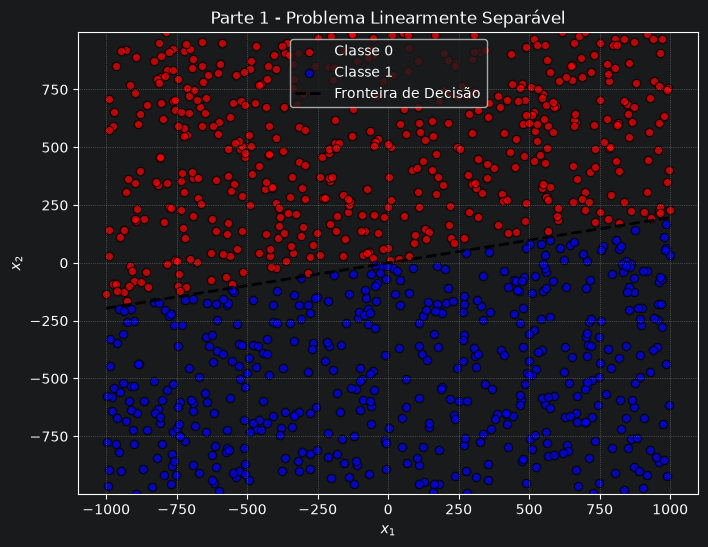

In [46]:
# resultados do item 5
print("RELATÓRIO DE CONVERGÊNCIA - PARTE I")
print(f"número total de ajustes no vetor de pesos: {modelo.n_ajustes_}")
print(f"número de épocas até a convergência: {modelo.n_epocas_}")
print(f"Vetor de pesos final obtido [w0, w1, w2]: {modelo.w_}")

#plotagem
visualizacao.plot_fronteira_decisao(
    X=X,
    y=y,
    modelo=modelo,
    titulo="Parte 1 - Problema Linearmente Separável"
);